# TP5 : Problème aux moindres carrés

L'objectif de ce TP consiste à reconstruire des images préalablement modifiées par une transformation non linéaire bruitée.

<img src="files/exo2.png" width="800" height="600"  >


Soit $I$ une image de taille $n\times m$.
Une transformation non linéaire notée $T$ est réalisée sur chaque niveau de gris $I_{ij}$ du pixel $(i,j)$ de l'image $I$. L'image modifiée après transformation est notée $J$, dont les éléments sont définis par :
\begin{equation}
\forall i\in \{1,..,n\}, \forall j \in\{1,..,m\}, \qquad J_{ij}=T(\alpha,\beta,I_{ij})=e^{-\alpha I_{ij}+\beta} \label{TransfoT}
\end{equation}
où $(\alpha,\beta)$ sont des paramètres réels.


On dispose d'une partie  de l'image modifiée par la transformation $T$ avec un bruit additif aléatoire et de la partie de l'image originale correspondante.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio


### Question 1 :
Ecrivez et résolvez la formulation matricielle du problème aux moindres carrés ordinaires (MCO) permettant d'estimer les paramètres $(\alpha,\beta)$ de la fonction $T$.




Techniquement

### Question 2 :
Codez la résolution du problème aux moindres carrés ordinaires à partir des données *Data.mat* et *DataMod.mat* issus respectivement des images originales et modifiées.

On pourra utiliser la fonction python **np.linalg.pinv**

(50, 50)


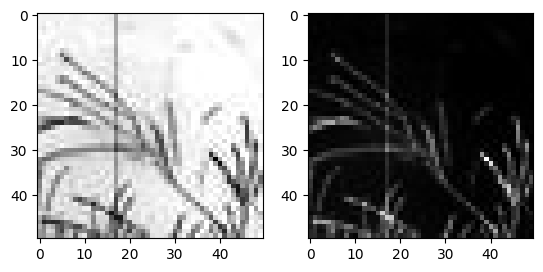

In [ ]:
Data = sio.loadmat('DataSG5.mat') # une partie de l'image originale
DataMod = sio.loadmat('DataSG5Mod.mat') # cette même partie de l'image modifée par la transformation T avec bruit additif

Data=np.asarray(Data['Data'])
DataMod=np.asarray(DataMod['DataMod'])
print(Data.shape) # dimension de la partie commune image originale et modifiée

fig = plt.figure(12)
ax1 = plt.subplot(1, 2, 1)
plt.imshow(Data, cmap='gray')
ax2=plt.subplot(1, 2, 2)
plt.imshow(DataMod, cmap='gray')

In [ ]:
Betha = np.log(DataMod.flatten())
I_flat = Data.flatten()

# Construction matrice X
# X avec deux colonnes
X = np.column_stack((I_flat, np.ones_like(I_flat)))

# Pseudo-inverse de X
Alpha = np.linalg.pinv(X)

# theta = [-alpha, beta]
theta = Alpha @ Betha

alpha_estimated = -theta[0]
beta_estimated = theta[1]

print(f"Alpha estimée: {alpha_estimated}")
print(f"Beta estimée: {beta_estimated}")

Alpha estimée: 5.000662115386243
Beta estimée: -0.009263917269486388


### Question 3 :
Déduire de la question 1 la fonction à appliquer pour reconstruire l'image.

à écrire

### Question 4 :
A partir des paramètres estimés et de l'image entière modifiée *ImMod.mat*, codez la reconstruction de l'image originale.

(357, 534)


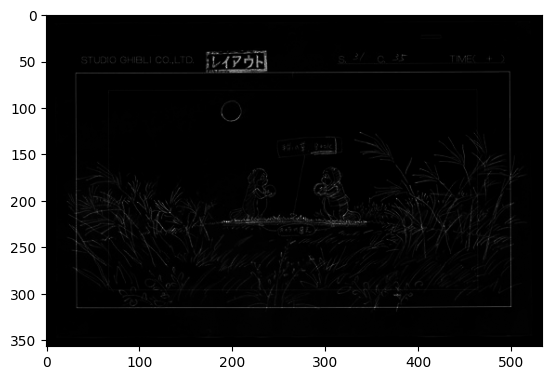

In [ ]:
ImMod = sio.loadmat('ImModSG5.mat') # image entière modifiée
ImMod=np.asarray(ImMod['ImMod'])
print(ImMod.shape) # dimension de l'image entière

plt.imshow(ImMod,cmap='gray')

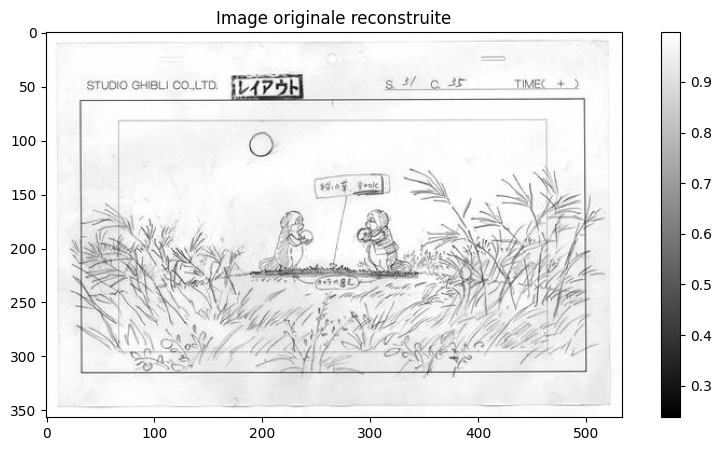

In [ ]:
ImReconstructed = (beta_estimated - np.log(ImMod)) / alpha_estimated

plt.figure(figsize=(10, 5))

plt.imshow(ImReconstructed, cmap='gray')
plt.title('Image originale reconstruite')
plt.colorbar()
plt.show()


# Quizz Studio Ghibli

D'autres images à reconstruire vous sont proposées.

Créez une fonction des étapes précédentes pour reconstruire l'image et testez vos connaissances sur les films de Hayao Miyazaki et Isao Takahata.
